# Assignment 5: Sentiment Analysis Using Python and Hugging Face Transformers

Step 1: Activate your environment

Step 2: Install required libraries

Step 3: Register Jupyter Notebook kernel


Step 4: Create your project folder

Step 5: Import the required libraries

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from transformers import pipeline

from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

print("All libraries imported successfully!")

All libraries imported successfully!


Step 6: Load the IMDb dataset

In [18]:
# Load IMDb dataset from Hugging Face

dataset = load_dataset("stanfordnlp/imdb")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


Step 7: Convert dataset into Pandas DataFrames

In [19]:
# Convert training and testing datasets into DataFrames

train_df = pd.DataFrame(dataset["train"])
test_df = pd.DataFrame(dataset["test"])

# Display first five records

print("Training Dataset:")
display(train_df.head())

print("Testing Dataset:")
display(test_df.head())

Training Dataset:


,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


Testing Dataset:


,text,label
0,I love sci-fi and am willing to put up with a ...,0
1,"Worth the entertainment value of a rental, esp...",0
2,its a totally average film with a few semi-alr...,0
3,STAR RATING: ***** Saturday Night **** Friday ...,0
4,"First off let me say, If you haven't enjoyed a...",0


Step 8: Understand the dataset

In [20]:
print("Training Dataset Shape:", train_df.shape)

print("\nTesting Dataset Shape:", test_df.shape)

print("\nDataset Information:")
train_df.info()

print("\nMissing Values:")
print(train_df.isnull().sum())

print("\nSentiment Labels:")
print(train_df["label"].value_counts())

Training Dataset Shape: (25000, 2)

Testing Dataset Shape: (25000, 2)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    25000 non-null  str  
 1   label   25000 non-null  int64
dtypes: int64(1), str(1)
memory usage: 32.0 MB

Missing Values:
text     0
label    0
dtype: int64

Sentiment Labels:
label
0    12500
1    12500
Name: count, dtype: int64


Step 9: Exploratory Data Analysis

9.1 Convert numeric labels into sentiment names


In [21]:
# Convert labels into sentiment names

train_df["sentiment"] = train_df["label"].map({
    0: "Negative",
    1: "Positive"
})

test_df["sentiment"] = test_df["label"].map({
    0: "Negative",
    1: "Positive"
})

print(train_df[["text", "label", "sentiment"]].head())

                                                text  label sentiment
0  I rented I AM CURIOUS-YELLOW from my video sto...      0  Negative
1  "I Am Curious: Yellow" is a risible and preten...      0  Negative
2  If only to avoid making this type of film in t...      0  Negative
3  This film was probably inspired by Godard's Ma...      0  Negative
4  Oh, brother...after hearing about this ridicul...      0  Negative


9.2 Check sentiment distribution

In [22]:
print("Sentiment Distribution:")
print(train_df["sentiment"].value_counts())

Sentiment Distribution:
sentiment
Negative    12500
Positive    12500
Name: count, dtype: int64


9.3 Visualize sentiment distribution

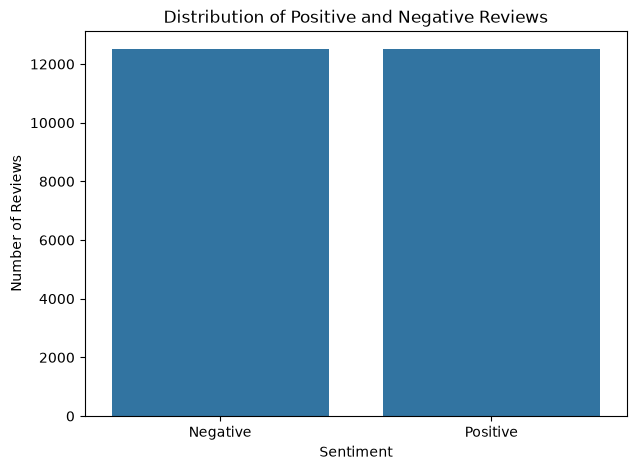

In [23]:
plt.figure(figsize=(7, 5))

sns.countplot(data=train_df, x="sentiment")

plt.title("Distribution of Positive and Negative Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

9.4 Analyze review length

In [24]:
# Calculate review length

train_df["review_length"] = train_df["text"].apply(
    lambda x: len(x.split())
)

print(train_df["review_length"].describe())

count    25000.000000
mean       233.787200
std        173.733032
min         10.000000
25%        127.000000
50%        174.000000
75%        284.000000
max       2470.000000
Name: review_length, dtype: float64


9.5 Visualize review length

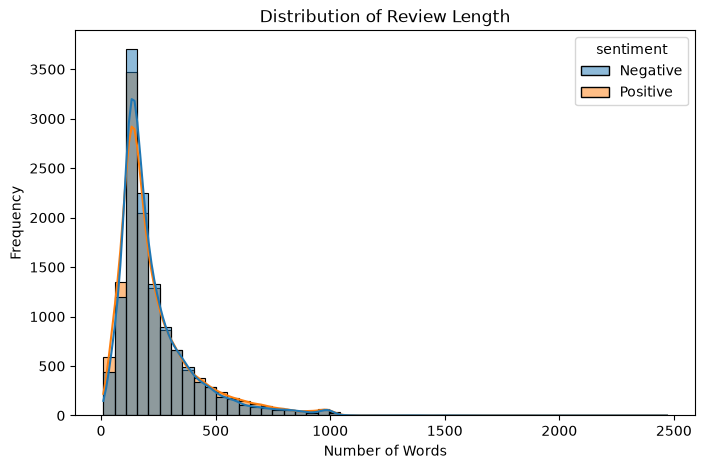

In [25]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=train_df,
    x="review_length",
    hue="sentiment",
    bins=50,
    kde=True
)

plt.title("Distribution of Review Length")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

Step 10: Load the Hugging Face DistilBERT model

In [26]:
# Load pre-trained DistilBERT sentiment analysis model

sentiment_model = pipeline(
    "sentiment-analysis",
    model="distilbert/distilbert-base-uncased-finetuned-sst-2-english",
    device=-1
)

print("DistilBERT model loaded successfully!")

Loading weights: 100%|██████████| 104/104 [00:00<00:00, 1147.16it/s]


DistilBERT model loaded successfully!


Step 11: Test the model with sample reviews

In [27]:
reviews = [
    "This movie was absolutely fantastic. I loved every moment!",
    "The movie was boring and disappointing. I wasted my time.",
    "The acting was good and the story was interesting.",
    "Terrible movie with poor acting and a very weak story."
]

predictions = sentiment_model(reviews)

for review, prediction in zip(reviews, predictions):
    print("Review:", review)
    print("Predicted Sentiment:", prediction["label"])
    print("Confidence:", round(prediction["score"], 4))
    print("-" * 60)

Review: This movie was absolutely fantastic. I loved every moment!
Predicted Sentiment: POSITIVE
Confidence: 0.9999
------------------------------------------------------------
Review: The movie was boring and disappointing. I wasted my time.
Predicted Sentiment: NEGATIVE
Confidence: 0.9998
------------------------------------------------------------
Review: The acting was good and the story was interesting.
Predicted Sentiment: POSITIVE
Confidence: 0.9999
------------------------------------------------------------
Review: Terrible movie with poor acting and a very weak story.
Predicted Sentiment: NEGATIVE
Confidence: 0.9998
------------------------------------------------------------


Step 12: Prepare IMDb test data

In [28]:
# Select 100 sample reviews

sample_df = test_df.sample(n=100, random_state=42).copy()

# Extract actual reviews and labels

reviews = sample_df["text"].tolist()
actual_labels = sample_df["label"].tolist()

print("Total Reviews Selected:", len(reviews))
print("Test data prepared successfully!")

Total Reviews Selected: 100
Test data prepared successfully!


Step 13: Predict sentiment using DistilBERT

In [29]:
# Generate predictions

predictions = sentiment_model(
    reviews,
    batch_size=8,
    truncation=True
)

# Convert predictions into numeric labels

predicted_labels = []

for prediction in predictions:
    if prediction["label"] == "POSITIVE":
        predicted_labels.append(1)
    else:
        predicted_labels.append(0)

print("Predictions completed successfully!")

Predictions completed successfully!


Step 14: Compare actual and predicted results

In [30]:
# Create comparison DataFrame

results_df = pd.DataFrame({
    "Review": reviews,
    "Actual Sentiment": actual_labels,
    "Predicted Sentiment": predicted_labels
})

# Convert numeric labels into names

results_df["Actual Sentiment"] = results_df["Actual Sentiment"].map({
    0: "Negative",
    1: "Positive"
})

results_df["Predicted Sentiment"] = results_df["Predicted Sentiment"].map({
    0: "Negative",
    1: "Positive"
})

display(results_df.head(10))

,Review,Actual Sentiment,Predicted Sentiment
0,I could not believe how terrible and boring th...,Negative,Negative
1,I rented Boogie Nights last week and I could t...,Positive,Positive
2,"First off, this movie is not near complete, my...",Negative,Negative
3,I watched this mini in the early eighties. Sam...,Positive,Positive
4,This movie was never intended as a big-budget ...,Positive,Positive
5,I thought this was an extremely bad movie. The...,Negative,Negative
6,This was one of the biggest pieces of crap I h...,Negative,Negative
7,I just watched it for the second time today an...,Positive,Negative
8,I've read through a lot of the comments here a...,Negative,Positive
9,I usually much prefer French movies over Ameri...,Negative,Negative


Step 15: Calculate model accuracy

In [31]:
accuracy = accuracy_score(actual_labels, predicted_labels)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 87.0 %


Step 16: Classification report

In [32]:
print("Classification Report:\n")

print(
    classification_report(
        actual_labels,
        predicted_labels,
        target_names=["Negative", "Positive"]
    )
)

Classification Report:

              precision    recall  f1-score   support

    Negative       0.85      0.87      0.86        47
    Positive       0.88      0.87      0.88        53

    accuracy                           0.87       100
   macro avg       0.87      0.87      0.87       100
weighted avg       0.87      0.87      0.87       100



Step 17: Confusion matrix

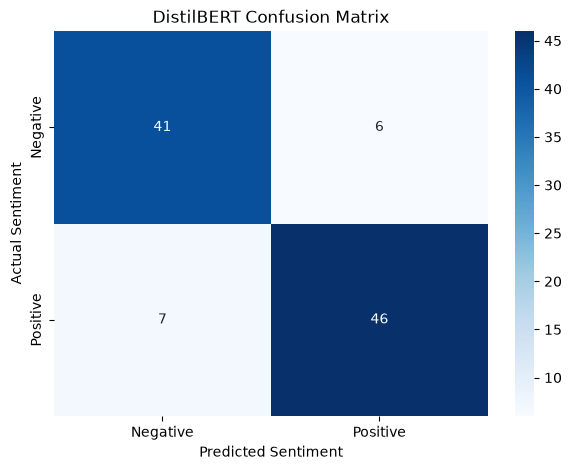

In [33]:
cm = confusion_matrix(actual_labels, predicted_labels)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative", "Positive"],
    yticklabels=["Negative", "Positive"]
)

plt.title("DistilBERT Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")

plt.show()

Step 18: Visualize actual vs predicted sentiment

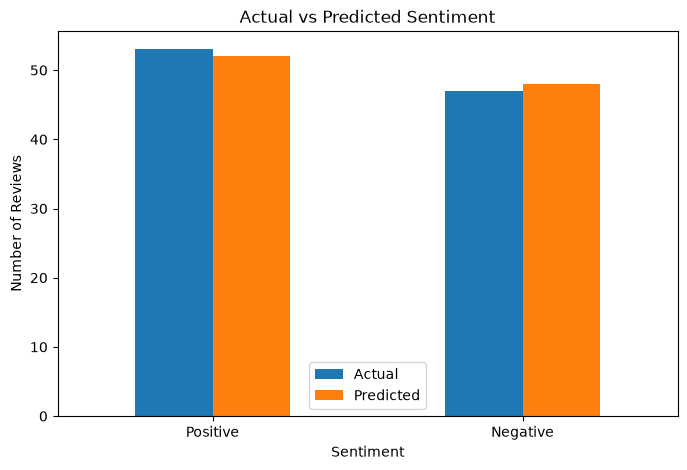

In [34]:
comparison = pd.DataFrame({
    "Actual": pd.Series(actual_labels).map({
        0: "Negative",
        1: "Positive"
    }),
    "Predicted": pd.Series(predicted_labels).map({
        0: "Negative",
        1: "Positive"
    })
})

comparison_counts = pd.DataFrame({
    "Actual": comparison["Actual"].value_counts(),
    "Predicted": comparison["Predicted"].value_counts()
})

comparison_counts.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Actual vs Predicted Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

Step 19: Test your own movie reviews

In [35]:
def analyze_review(review):

    result = sentiment_model(review)[0]

    print("\nMovie Review:")
    print(review)

    print("\nPredicted Sentiment:", result["label"])

    print("Confidence Score:", round(result["score"] * 100, 2), "%")


# Test custom reviews

analyze_review(
    "This movie is amazing. The actors performed brilliantly!"
)

analyze_review(
    "The movie was very boring. I did not enjoy it at all."
)


Movie Review:
This movie is amazing. The actors performed brilliantly!

Predicted Sentiment: POSITIVE
Confidence Score: 99.99 %

Movie Review:
The movie was very boring. I did not enjoy it at all.

Predicted Sentiment: NEGATIVE
Confidence Score: 99.97 %


Step 21: Save your project results

In [36]:
# Save prediction results

results_df.to_csv(
    "sentiment_analysis_results.csv",
    index=False
)

print("Results saved successfully!")

Results saved successfully!


Step 22: Save the model evaluation report


In [37]:
from sklearn.metrics import classification_report

report = classification_report(
    actual_labels,
    predicted_labels,
    target_names=["Negative", "Positive"]
)

with open("model_evaluation_report.txt", "w") as file:
    file.write("SENTIMENT ANALYSIS MODEL EVALUATION\n")
    file.write("=" * 45 + "\n\n")
    file.write(f"Accuracy: {accuracy * 100:.2f}%\n\n")
    file.write(report)

print("Evaluation report saved successfully!")

Evaluation report saved successfully!


## Conclusion

In this project, I developed a Sentiment Analysis system using Python and Hugging Face Transformers.

The IMDb movie review dataset was used to classify movie reviews into Positive and Negative categories. Data exploration and visualization were performed to understand the dataset.

A pre-trained DistilBERT model was implemented using the Hugging Face Transformers pipeline. The model was tested on sample reviews and evaluated using accuracy, precision, recall, F1-score, and a confusion matrix.

The project demonstrates how Transformer-based NLP models can be used to understand text sentiment and automate review classification.

**Future Scope:**
- Analyze larger review datasets.
- Build an interactive Streamlit application.
- Support additional languages.
- Fine-tune DistilBERT on domain-specific datasets.